# 06　4月の企業除去試行を、全時刻と条件の違いで読む

既存の固定版を変更せず、PV・風力・原子力を残した**名参照代理による調整供給除去**を比較します。所有・契約供給の確定、正式RSI、企業不可欠性の認定ではありません。

見る順番：①全1,440コマの状態 → ②同じ時刻の送電比較 → ③停止情報の不明部分 → ④9地域同時成立とJERA。詳細は `reports/22_april_trial_comparison/README.md` です。各図に分母を記載します。

In [1]:
import sys
from pathlib import Path

import pandas as pd
from IPython.display import Image, display

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
OUT = ROOT / "data/interim/occto/april_trial_comparison/20261027_comparison_v1"
REPORT = ROOT / "reports/22_april_trial_comparison"
QA = REPORT / "qa"
AREAS = ["北海道", "東北", "東京", "中部", "北陸", "関西", "中国", "四国", "九州"]


def show(name):
    display(Image(filename=str(REPORT / "figures" / (name + ".png"))))


print("保存比較版:", OUT.name)
print("実データはローカルdata/。GitHubでは保存された図・出力表も参照できます。")

保存比較版: 20261027_comparison_v1
実データはローカルdata/。GitHubでは保存された図・出力表も参照できます。


## 1．全時刻の状態

各棒は全1,440コマです。有効コマだけの1未満割合は別の分母です。地理順であり、地域順位ではありません。重複する理由flagは積み上げず、元の主statusを使います。

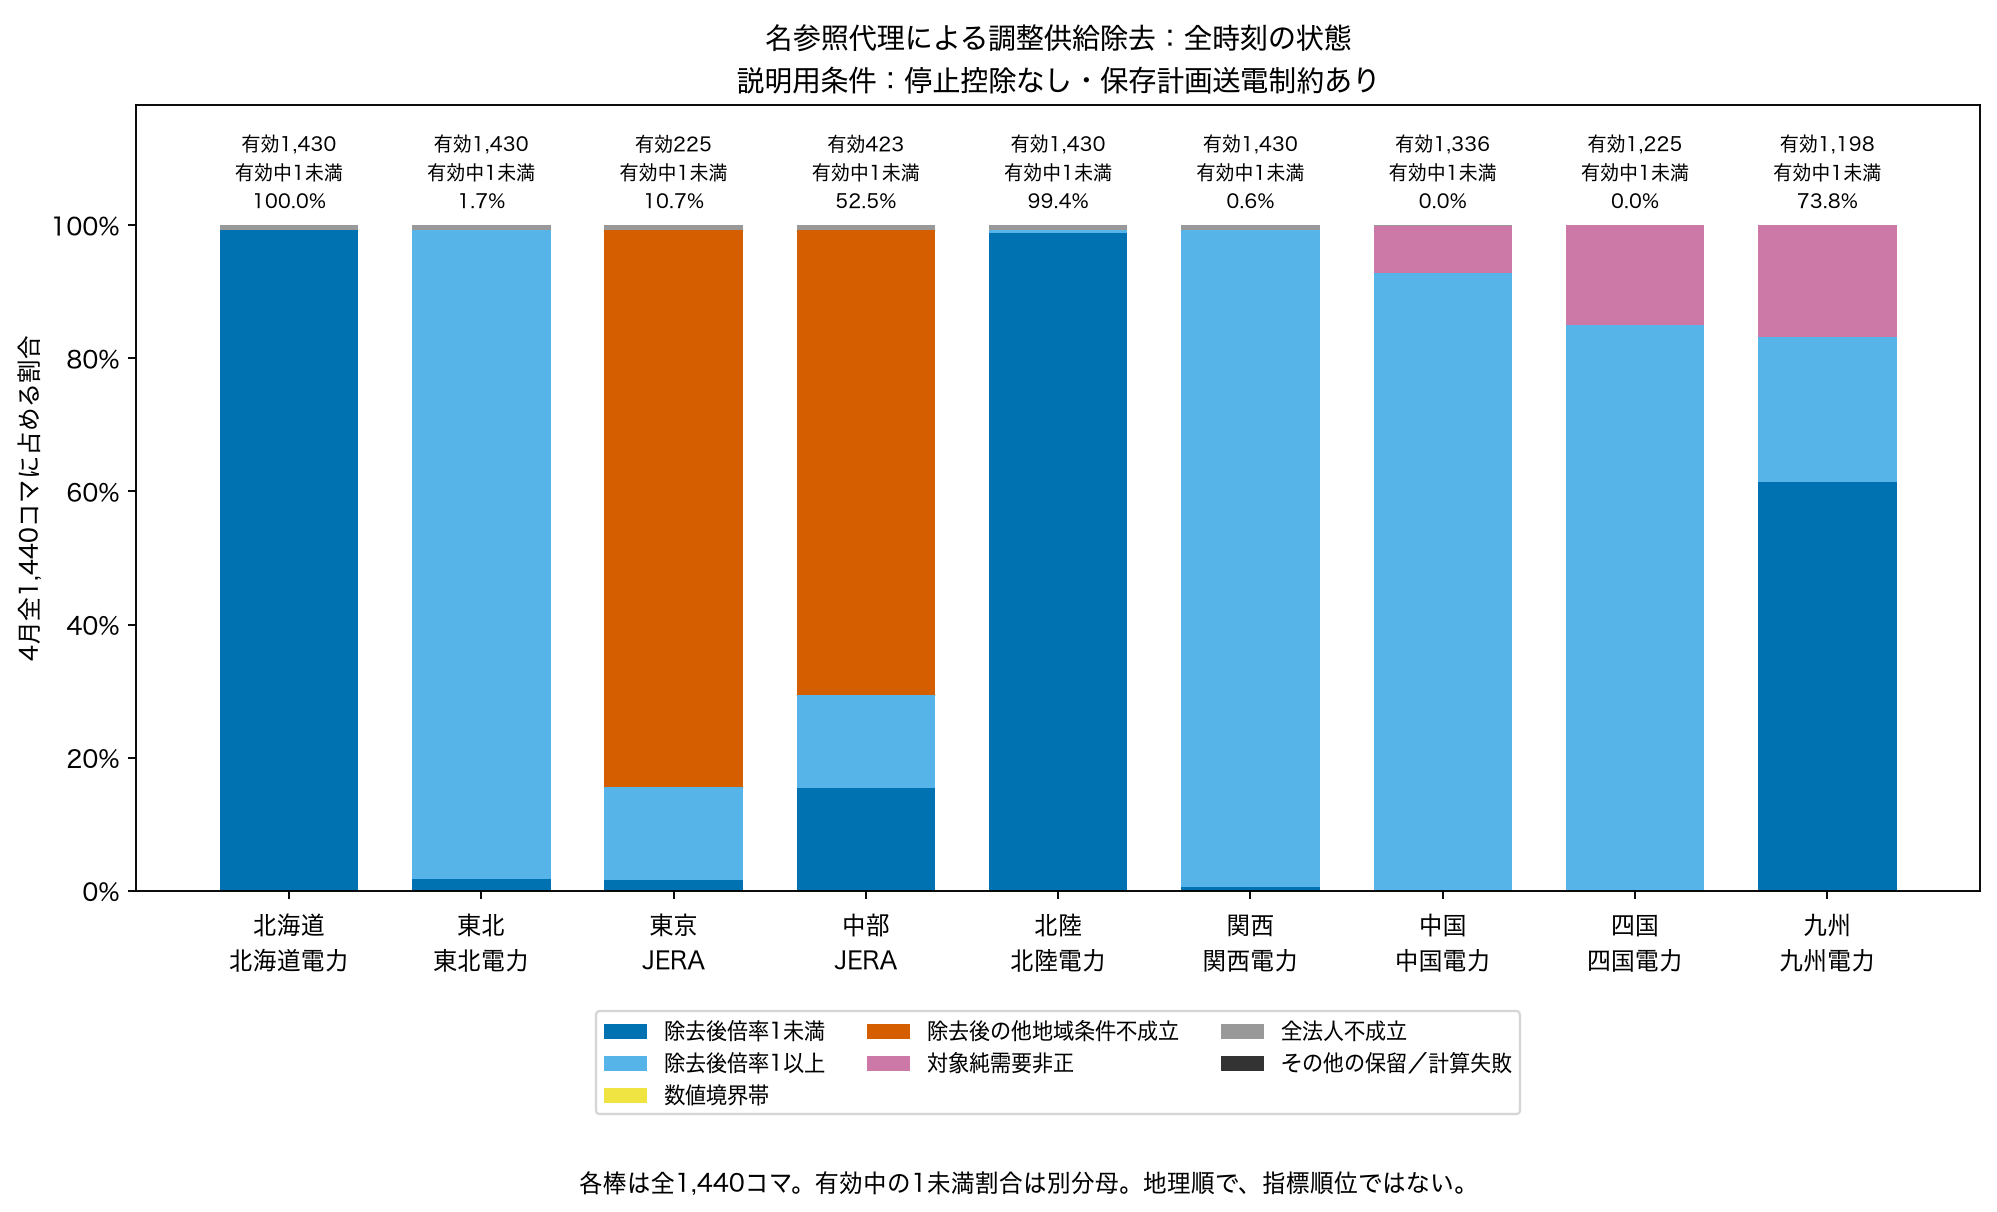

category,all_firms_infeasible,at_least_one,below_one,nonpositive_target_net,numerical_boundary,other_held,removed_other_regions_infeasible
target_area,,,,,,,
北海道,10,0,1430,0,0,0,0
東北,10,1405,25,0,0,0,0
東京,10,201,24,0,0,0,1205
中部,10,201,222,0,0,0,1007
北陸,10,8,1422,0,0,0,0
関西,10,1422,8,0,0,0,0
中国,2,1336,0,102,0,0,0
四国,0,1225,0,215,0,0,0
九州,0,314,884,242,0,0,0


In [2]:
show("01_all_time_states")
shares = pd.read_csv(QA / "all_time_state_shares.csv")
display(shares.pivot(index="target_area", columns="category", values="count").reindex(AREAS))

## 2．送電制約だけを変えた比較

対象ごとの**両条件共通有効時刻**を使います。全対象共通52コマへは限定しません。0〜2倍の表示でも、範囲外の値は分母から除きません。全範囲表示も続けて確認できます。包絡なしは輸送の制限を解除した比較仮定です。

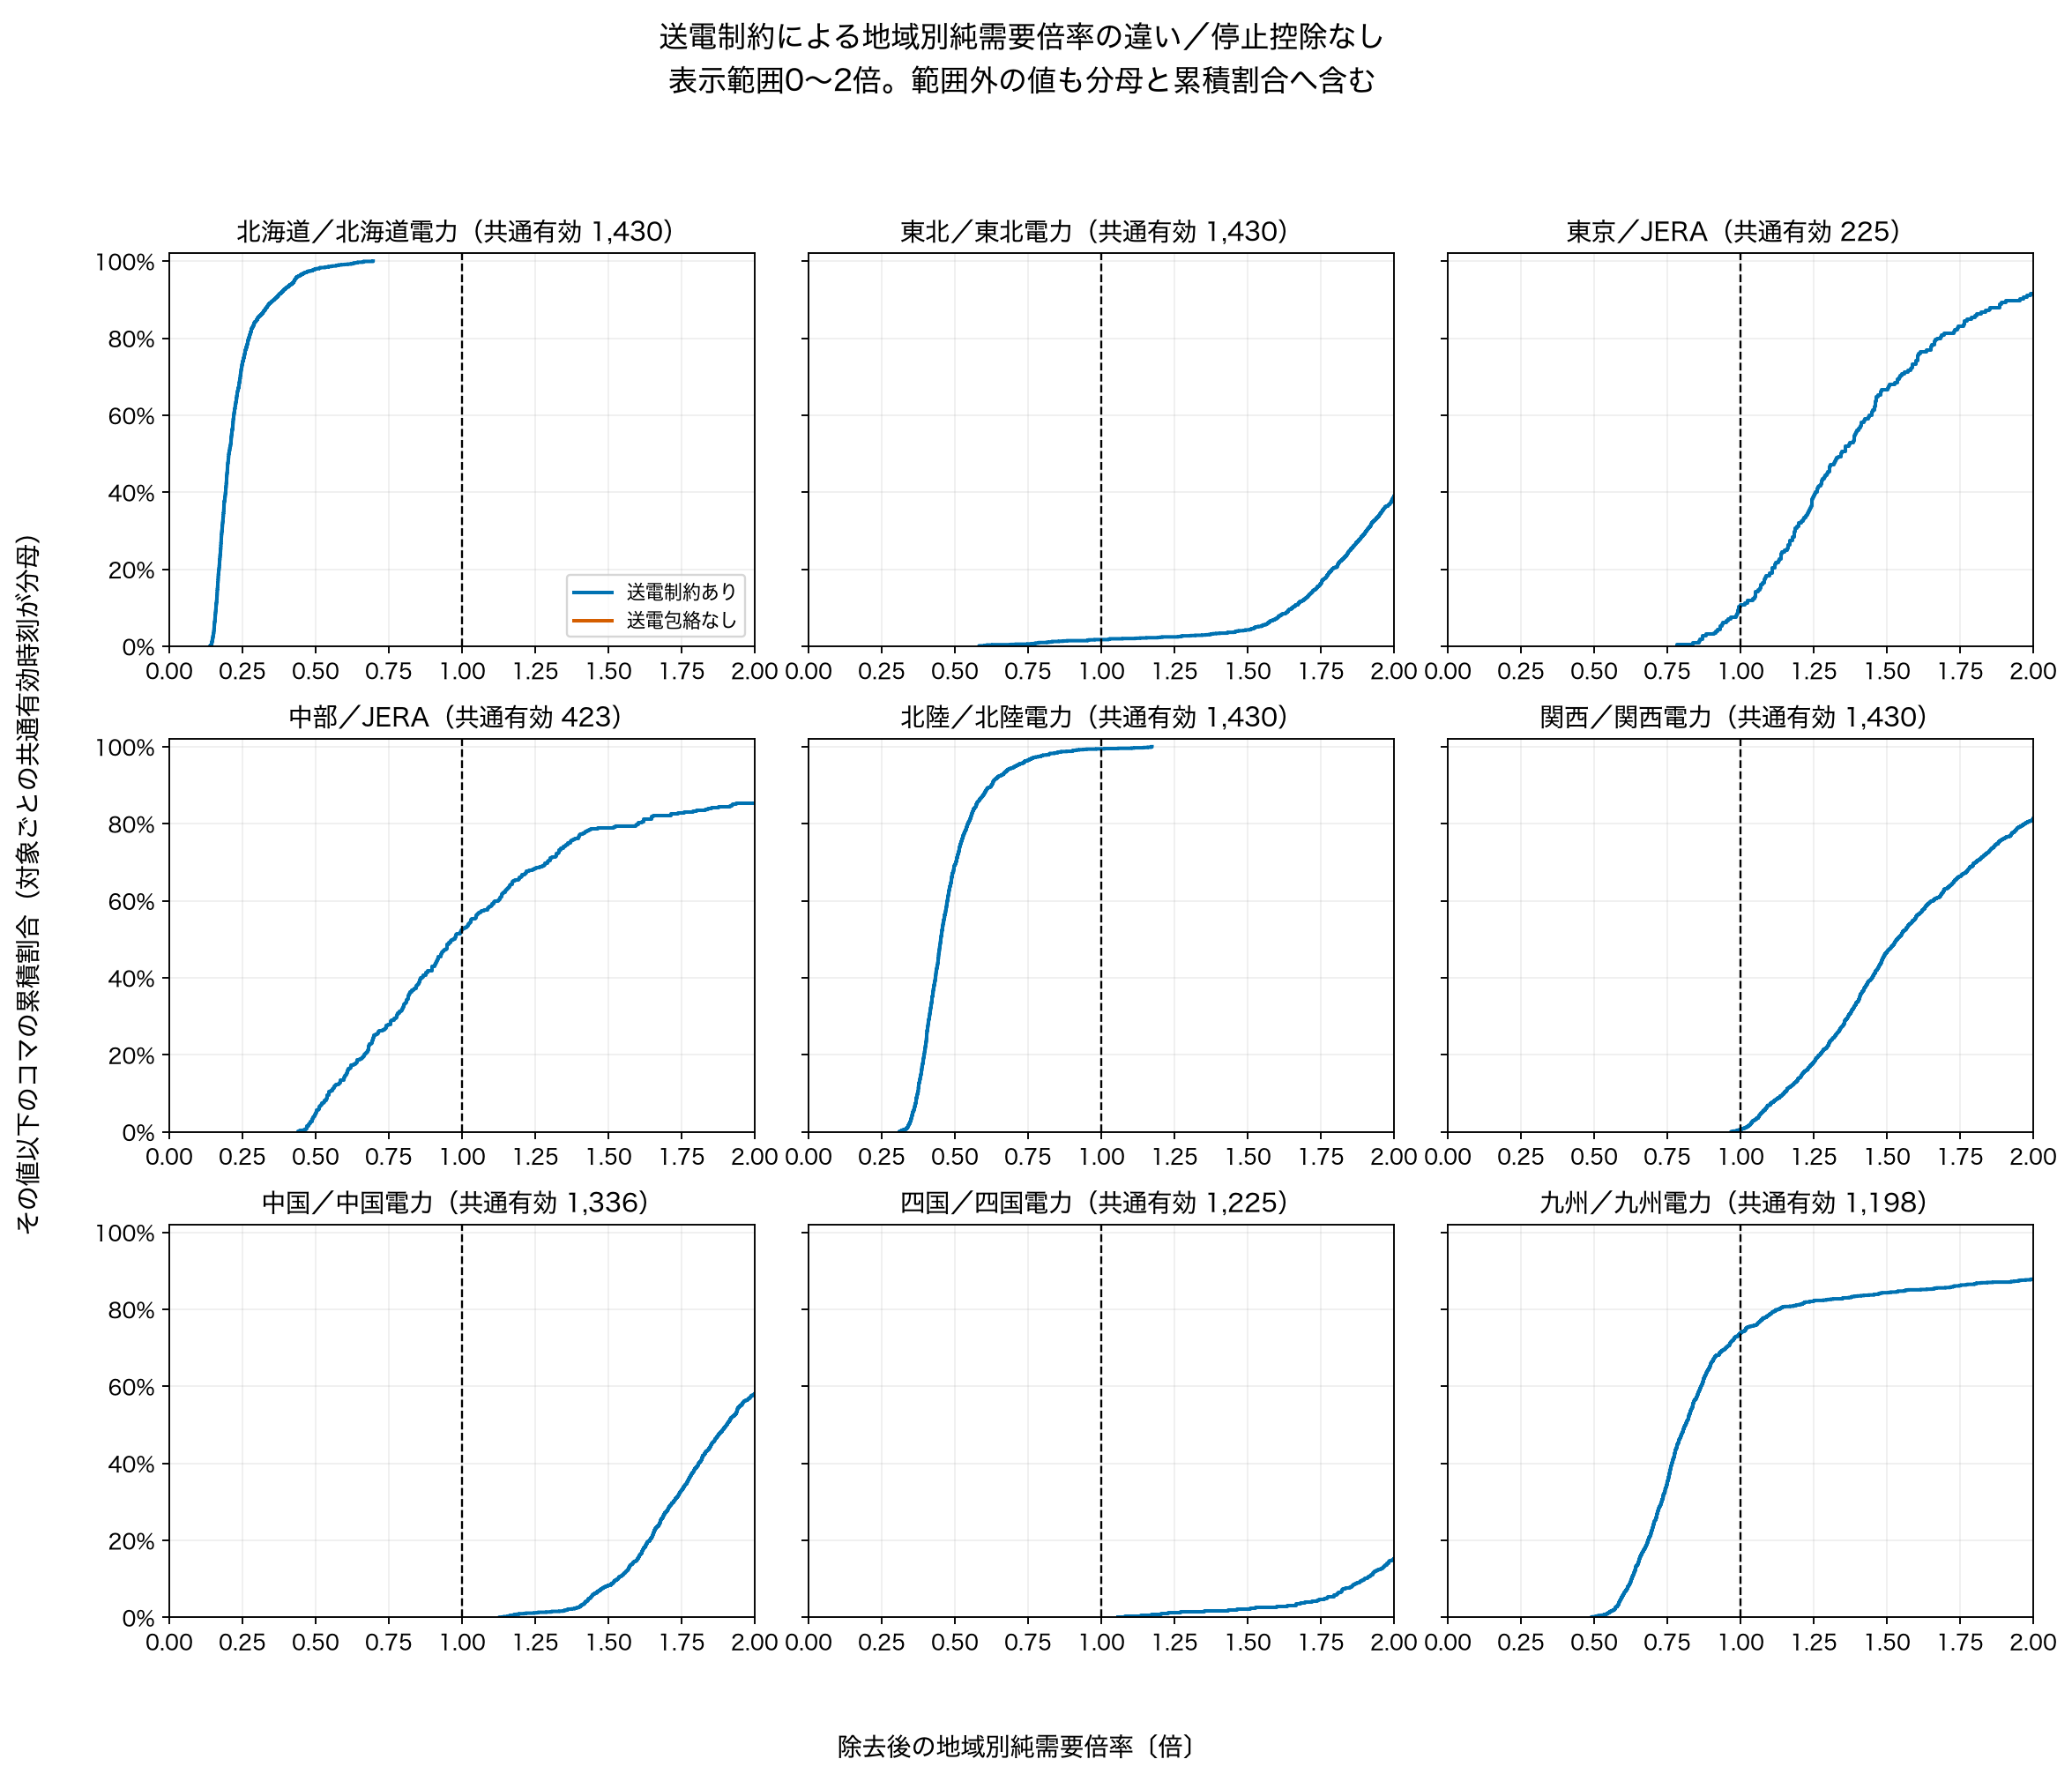

,entity,all_times,common_valid,network_only_valid,relaxed_only_valid,neither_valid,below_one_network_common,below_one_relaxed_common,median_network_common,median_relaxed_common
target_area,,,,,,,,,,
北海道,北海道電力株式会社,1440,1430,0,10,0,1430,0,0.203504,27.851923
東北,東北電力株式会社,1440,1430,0,10,0,25,0,2.173022,12.235156
東京,株式会社JERA,1440,225,0,1215,0,24,0,1.343099,5.199849
中部,株式会社JERA,1440,423,0,1017,0,222,0,0.971023,8.852475
北陸,北陸電力株式会社,1440,1430,0,10,0,1422,0,0.451382,26.722703
関西,関西電力株式会社,1440,1430,0,10,0,8,0,1.534946,8.754938
中国,中国電力株式会社,1440,1336,0,2,102,0,0,1.904967,15.857856
四国,四国電力株式会社,1440,1225,0,0,215,0,0,2.565789,50.271543
九州,九州電力株式会社,1440,1198,0,0,242,884,0,0.812100,13.878404


In [3]:
show("03_network_ecdf_near_one")
display(pd.read_csv(QA / "network_validity_summary.csv").set_index("target_area").reindex(AREAS))

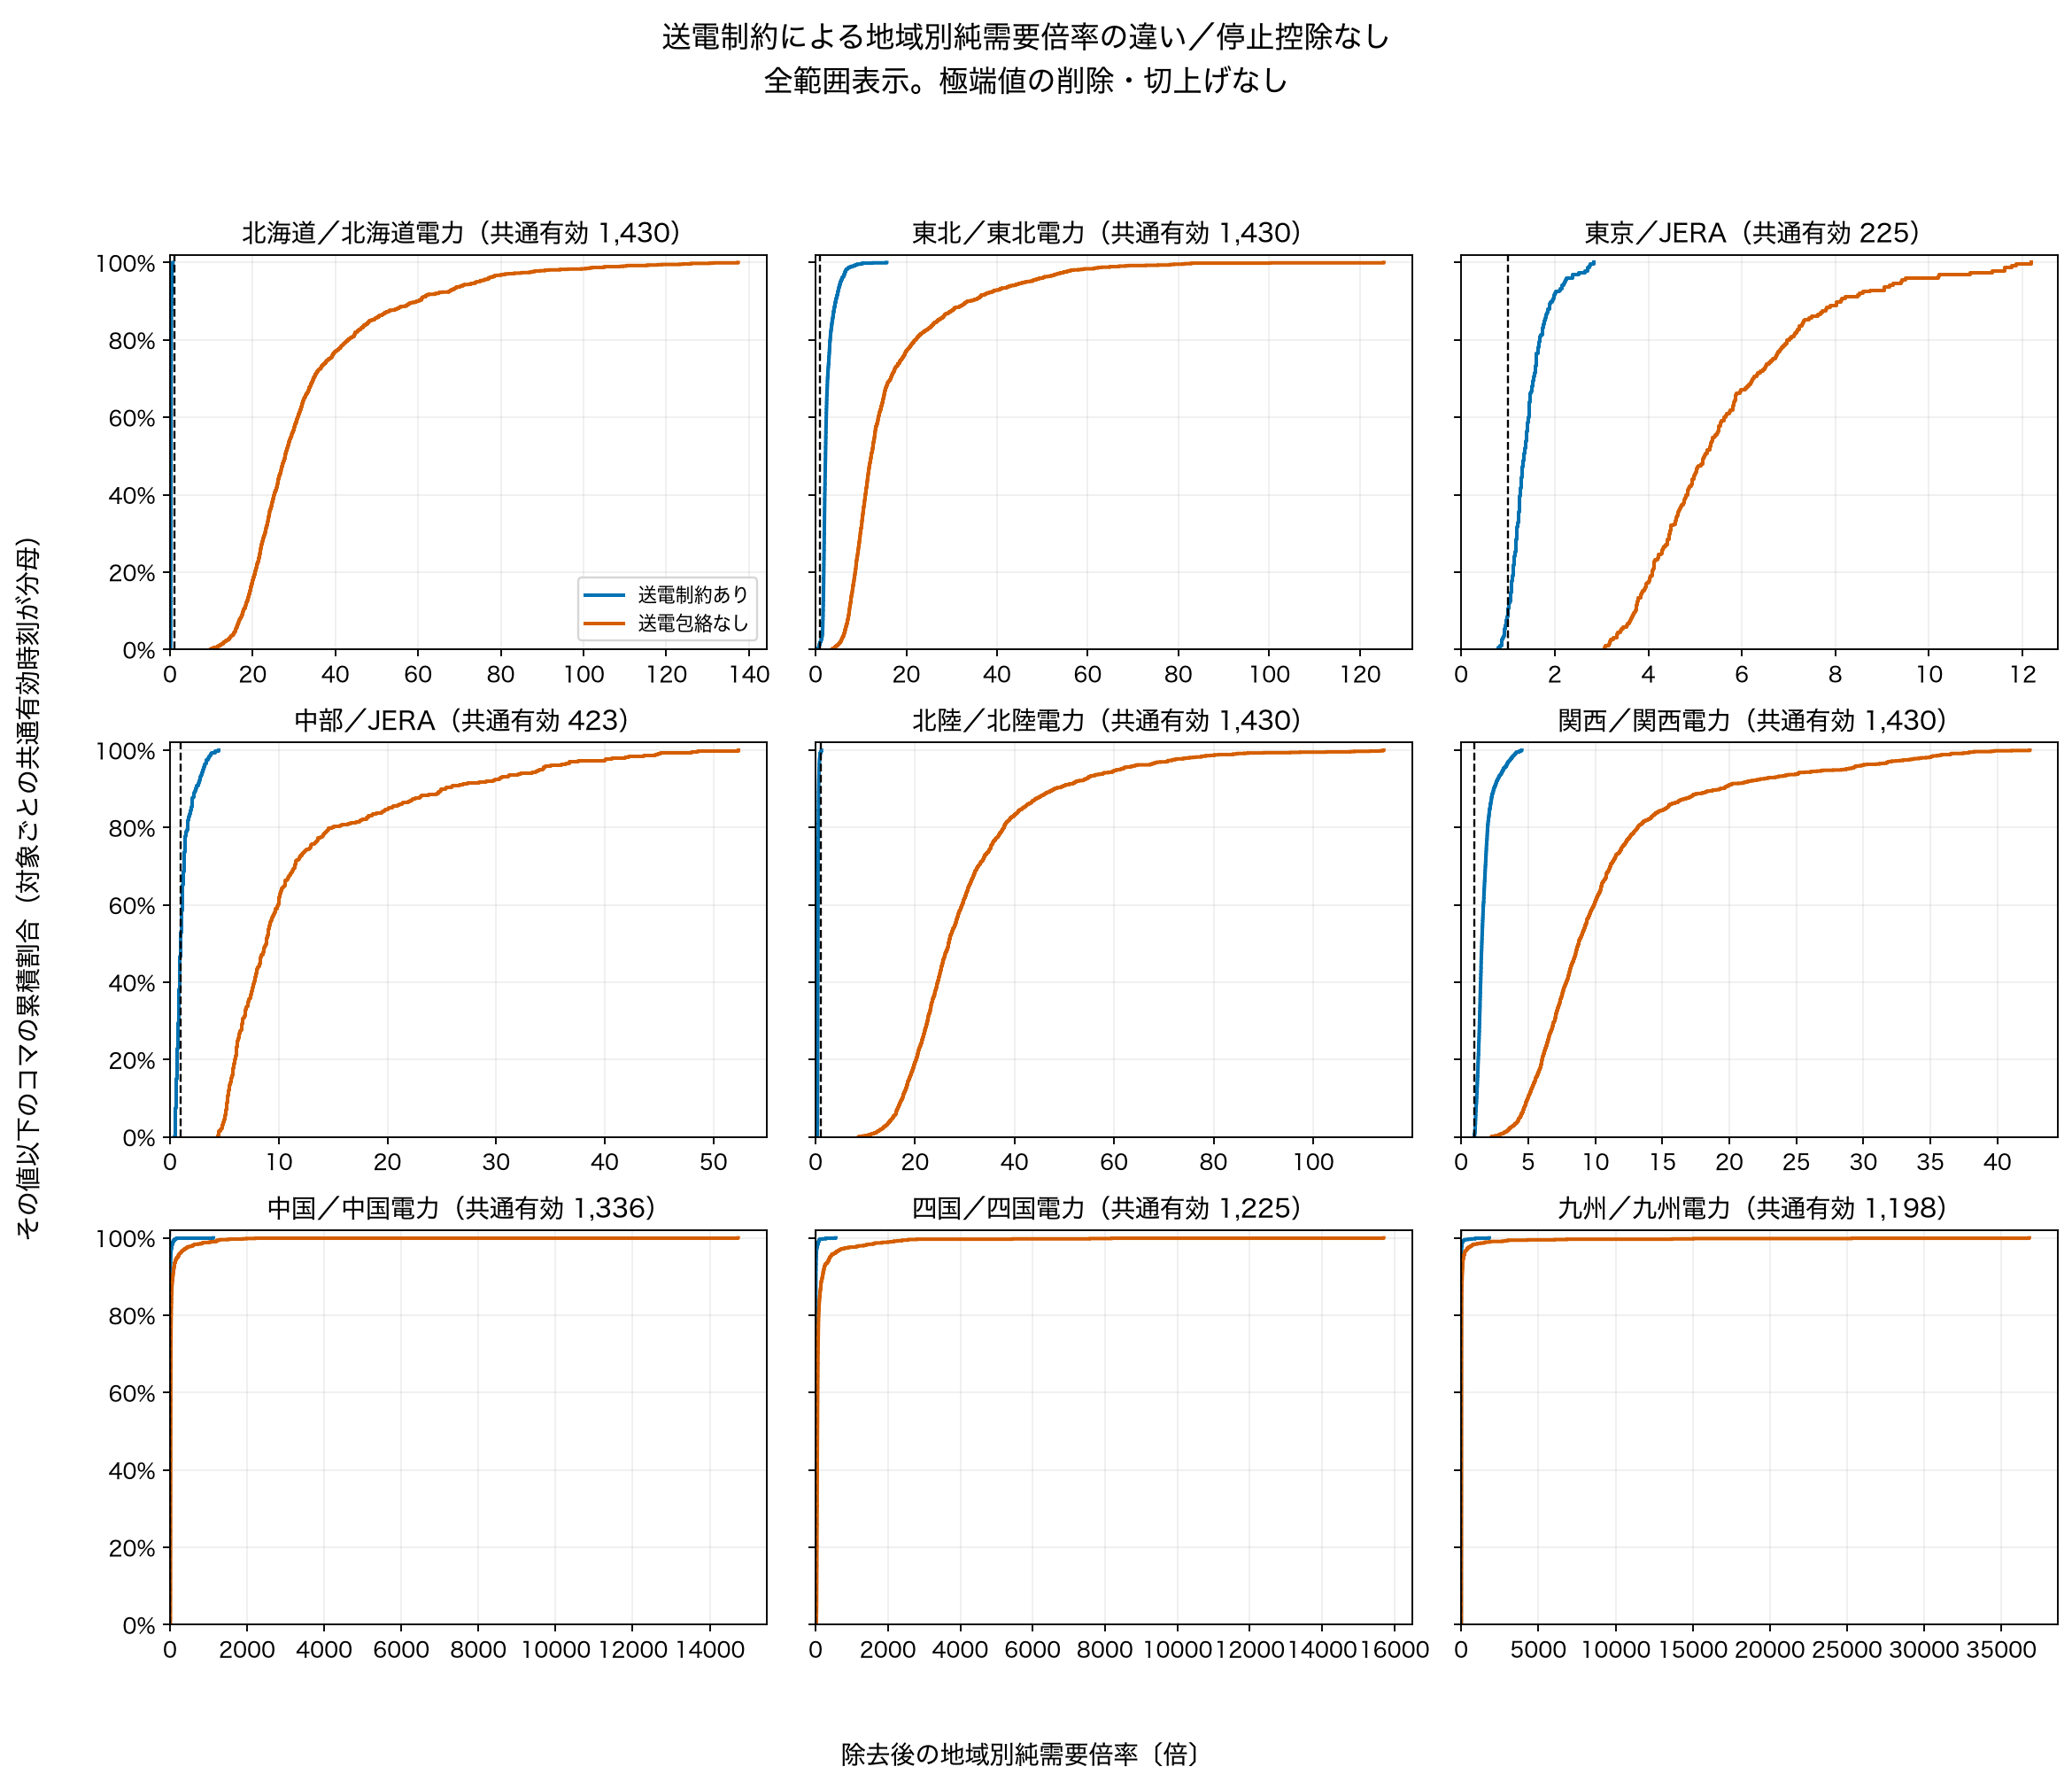

,common_valid,network_above_zoom_2,relaxed_above_zoom_2,network_max,relaxed_max
target_area,,,,,
北海道,1430,0,1430,0.696357,137.398957
東北,1430,874,1430,15.679028,125.287685
東京,225,19,225,2.826623,12.182605
中部,423,62,423,4.479756,52.290223
北陸,1430,0,1430,1.173096,114.235678
関西,1430,267,1430,4.521881,42.418162
中国,1336,561,1336,1123.675714,14736.852857
四国,1225,1040,1225,557.833333,15706.828333
九州,1198,146,1198,1817.000000,36810.485000


,target_area,entity,status_network,status_relaxed,category_network,category_relaxed,count
0,中国,中国電力株式会社,all_firms_infeasible,valid,all_firms_infeasible,at_least_one,2
1,中国,中国電力株式会社,nonpositive_target_net,nonpositive_target_net,nonpositive_target_net,nonpositive_target_net,102
2,中国,中国電力株式会社,valid,valid,at_least_one,at_least_one,1336
3,中部,株式会社JERA,all_firms_infeasible,valid,all_firms_infeasible,at_least_one,10
4,中部,株式会社JERA,removed_other_regions_infeasible,valid,removed_other_regions_infeasible,at_least_one,1002
5,中部,株式会社JERA,removed_other_regions_infeasible,valid,removed_other_regions_infeasible,below_one,5
6,中部,株式会社JERA,valid,valid,at_least_one,at_least_one,201
7,中部,株式会社JERA,valid,valid,below_one,at_least_one,222
8,九州,九州電力株式会社,nonpositive_target_net,nonpositive_target_net,nonpositive_target_net,nonpositive_target_net,242
9,九州,九州電力株式会社,valid,valid,at_least_one,at_least_one,314


In [4]:
show("02_network_ecdf_full_range")
display(pd.read_csv(QA / "ecdf_display_windows.csv").set_index("target_area").reindex(AREAS))
display(pd.read_csv(QA / "network_status_transitions.csv"))

## 3．停止情報の不明部分を参照上限へ戻すとどう変わるか

図は58,852行版・早端・全停止0・保存送電制約ありの一組です。最終baselineではありません。表には全8組・両送電条件を残します。対象企業の戻し分は除去後に除かれ、残る上限を増やすのは他者分です。全法人の成立判定が変わる経路とは分けます。

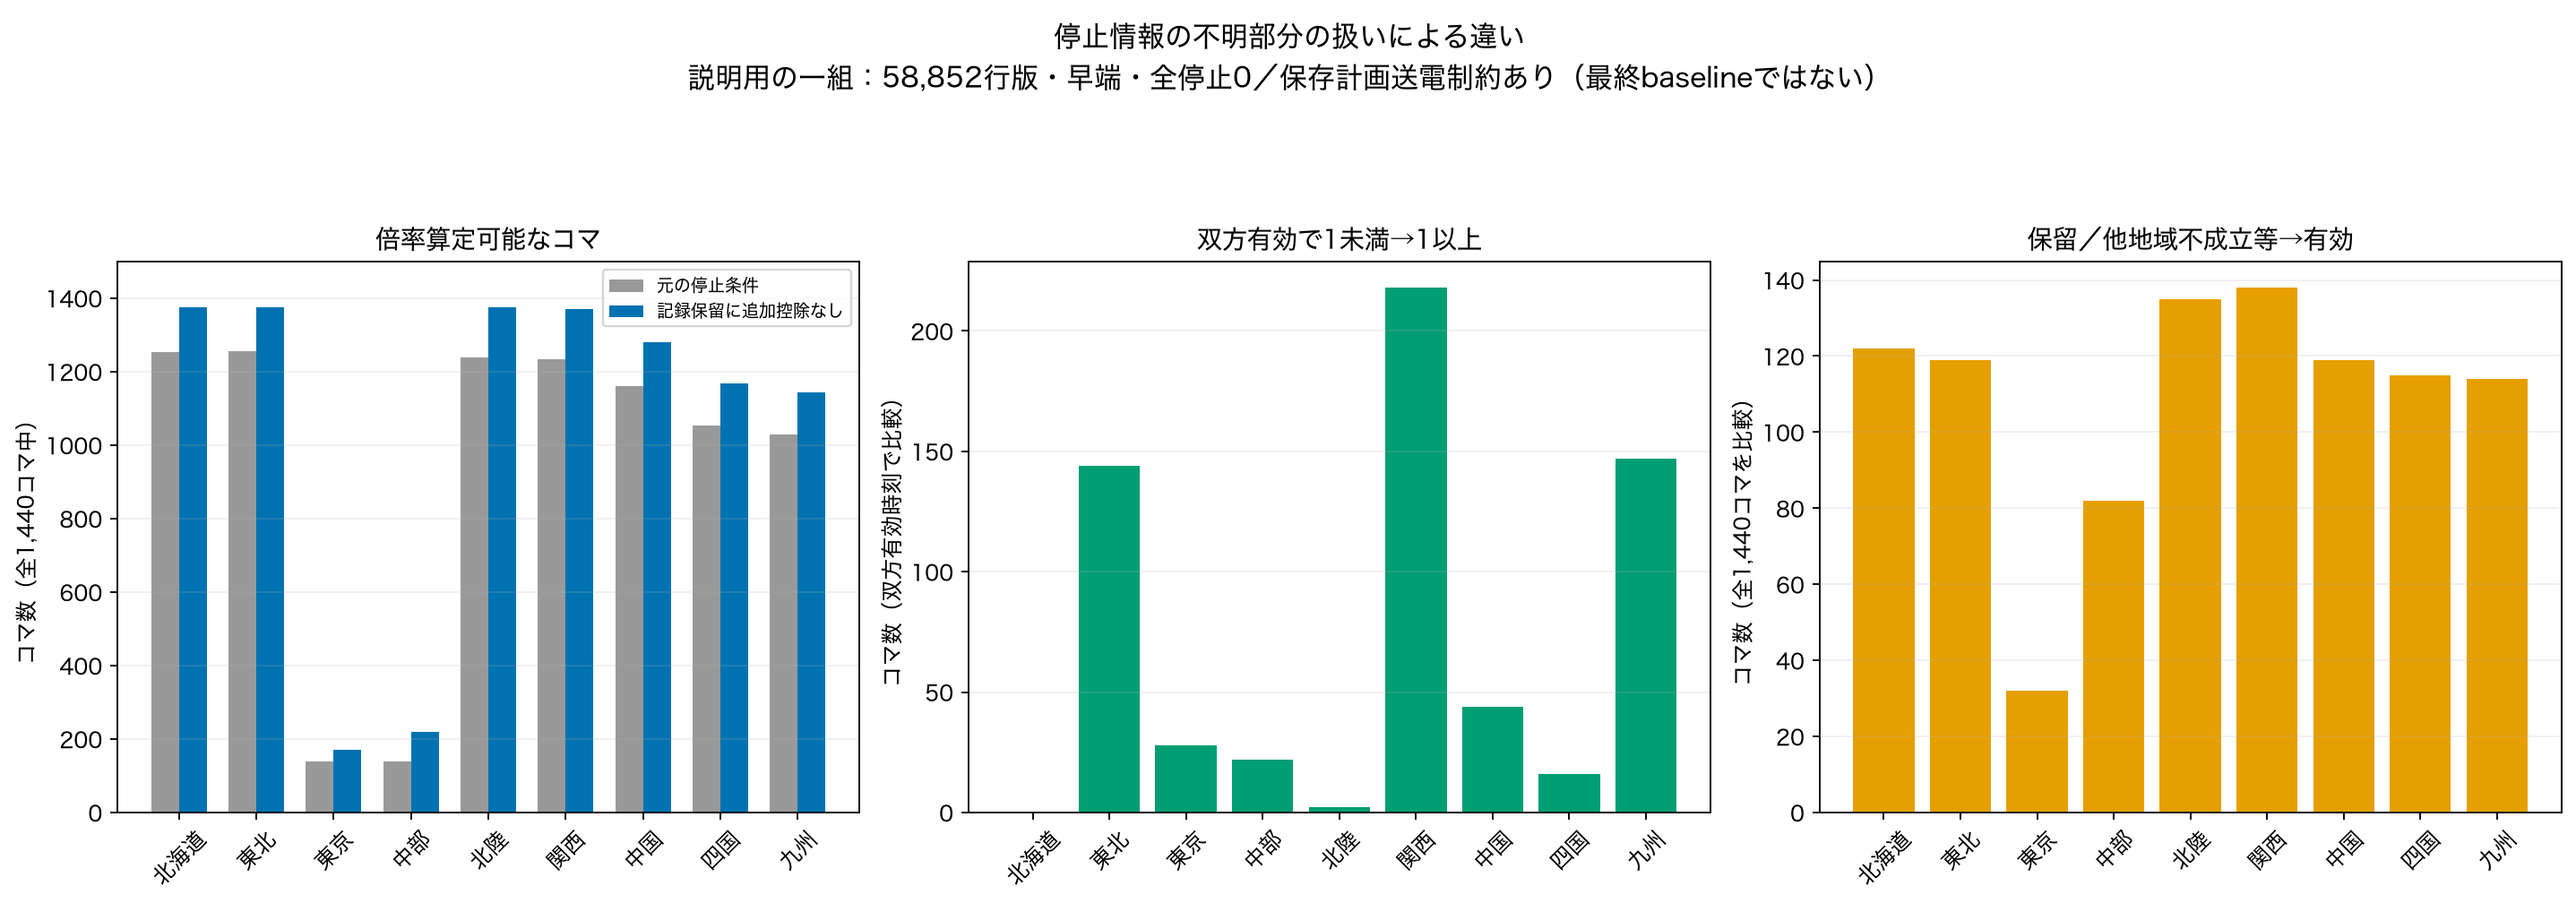

,original_scenario,network_scenario,all_times,valid_before,valid_after,both_valid,lambda_difference_min,lambda_difference_median,lambda_difference_max,below_to_above,above_to_below,became_valid_from_all_firms_infeasible,became_valid_from_other_regions_infeasible,became_valid_from_other_held
target_area,,,,,,,,,,,,,,
北海道,58852_early__full_stop_zero,saved_plan_constraints,1440,1252,1374,1252,0.000000,0.000000,0.079513,0,0,119,3,0
東北,58852_early__full_stop_zero,saved_plan_constraints,1440,1255,1374,1255,0.013850,0.070200,0.786017,144,0,119,0,0
東京,58852_early__full_stop_zero,saved_plan_constraints,1440,138,170,138,0.104997,0.161203,0.263528,28,0,0,32,0
中部,58852_early__full_stop_zero,saved_plan_constraints,1440,138,220,138,0.064655,0.177018,0.733908,22,0,0,82,0
北陸,58852_early__full_stop_zero,saved_plan_constraints,1440,1239,1374,1239,0.031664,0.044391,0.421591,2,0,119,16,0
関西,58852_early__full_stop_zero,saved_plan_constraints,1440,1233,1371,1233,0.000000,0.053879,0.472055,218,0,116,22,0
中国,58852_early__full_stop_zero,saved_plan_constraints,1440,1161,1280,1161,0.000000,0.206856,100.000000,44,0,119,0,0
四国,58852_early__full_stop_zero,saved_plan_constraints,1440,1054,1169,1054,0.490654,0.806452,175.000000,16,0,115,0,0
九州,58852_early__full_stop_zero,saved_plan_constraints,1440,1029,1143,1029,0.151046,0.461942,1056.000000,147,0,114,0,0


,original_scenario,entity_code,time_keys,restored_total_reference_mw_min,restored_total_reference_mw_mean,restored_total_reference_mw_max,restored_target_reference_mw_min,restored_target_reference_mw_mean,restored_target_reference_mw_max,restored_other_reference_mw_min,restored_other_reference_mw_mean,restored_other_reference_mw_max
0,58852_early__full_stop_zero,chugoku,1440,11392.0,15274.447014,18064.65,890.0,1912.391667,3484.0,10502.0,13362.055347,15468.65
1,58852_early__full_stop_zero,hokkaido,1440,11392.0,15274.447014,18064.65,925.0,925.937500,1275.0,10467.0,14348.509514,17139.65
2,58852_early__full_stop_zero,hokuriku,1440,11392.0,15274.447014,18064.65,240.0,240.000000,240.0,11152.0,15034.447014,17824.65
3,58852_early__full_stop_zero,jera,1440,11392.0,15274.447014,18064.65,1070.0,1189.464028,2258.2,10322.0,14084.982986,16907.45
4,58852_early__full_stop_zero,kansai,1440,11392.0,15274.447014,18064.65,1439.0,3013.492708,4895.0,9347.0,12260.954306,14901.00
5,58852_early__full_stop_zero,kyushu,1440,11392.0,15274.447014,18064.65,1160.0,1446.250000,2060.0,10232.0,13828.197014,16604.65
6,58852_early__full_stop_zero,shikoku,1440,11392.0,15274.447014,18064.65,0.0,9.866667,296.0,11392.0,15264.580347,18064.65
7,58852_early__full_stop_zero,tohoku,1440,11392.0,15274.447014,18064.65,0.0,33.493056,1000.0,10552.0,15240.953958,18064.65


In [5]:
show("04_stop_record_restoration_example")
stop = pd.read_csv(QA / "stop_pair_summary.csv")
display(
    stop[
        stop.original_scenario.eq("58852_early__full_stop_zero")
        & stop.network_scenario.eq("saved_plan_constraints")
    ]
    .set_index("target_area")
    .reindex(AREAS)
)
restored = pd.read_csv(QA / "restored_reference_summary.csv")
display(restored[restored.original_scenario.eq("58852_early__full_stop_zero")])

## 4．9地域の元の純需要を同時に満たせるか

この検査は倍率を使いません。8法人を各1回数え、JERAは東京・中部の両方で同じ法人です。全法人時から不成立を別にしています。JERAは除去後も成立201コマ、除去により不成立1,229コマ、全法人時から不成立10コマです。

東京の1未満24＋他地域不成立1,205＝1,229。中部の1未満222＋他地域不成立1,007＝1,229。中央値1.343／0.971は、それぞれ倍率が有効な225／423コマの値で、全時刻の結論ではありません。

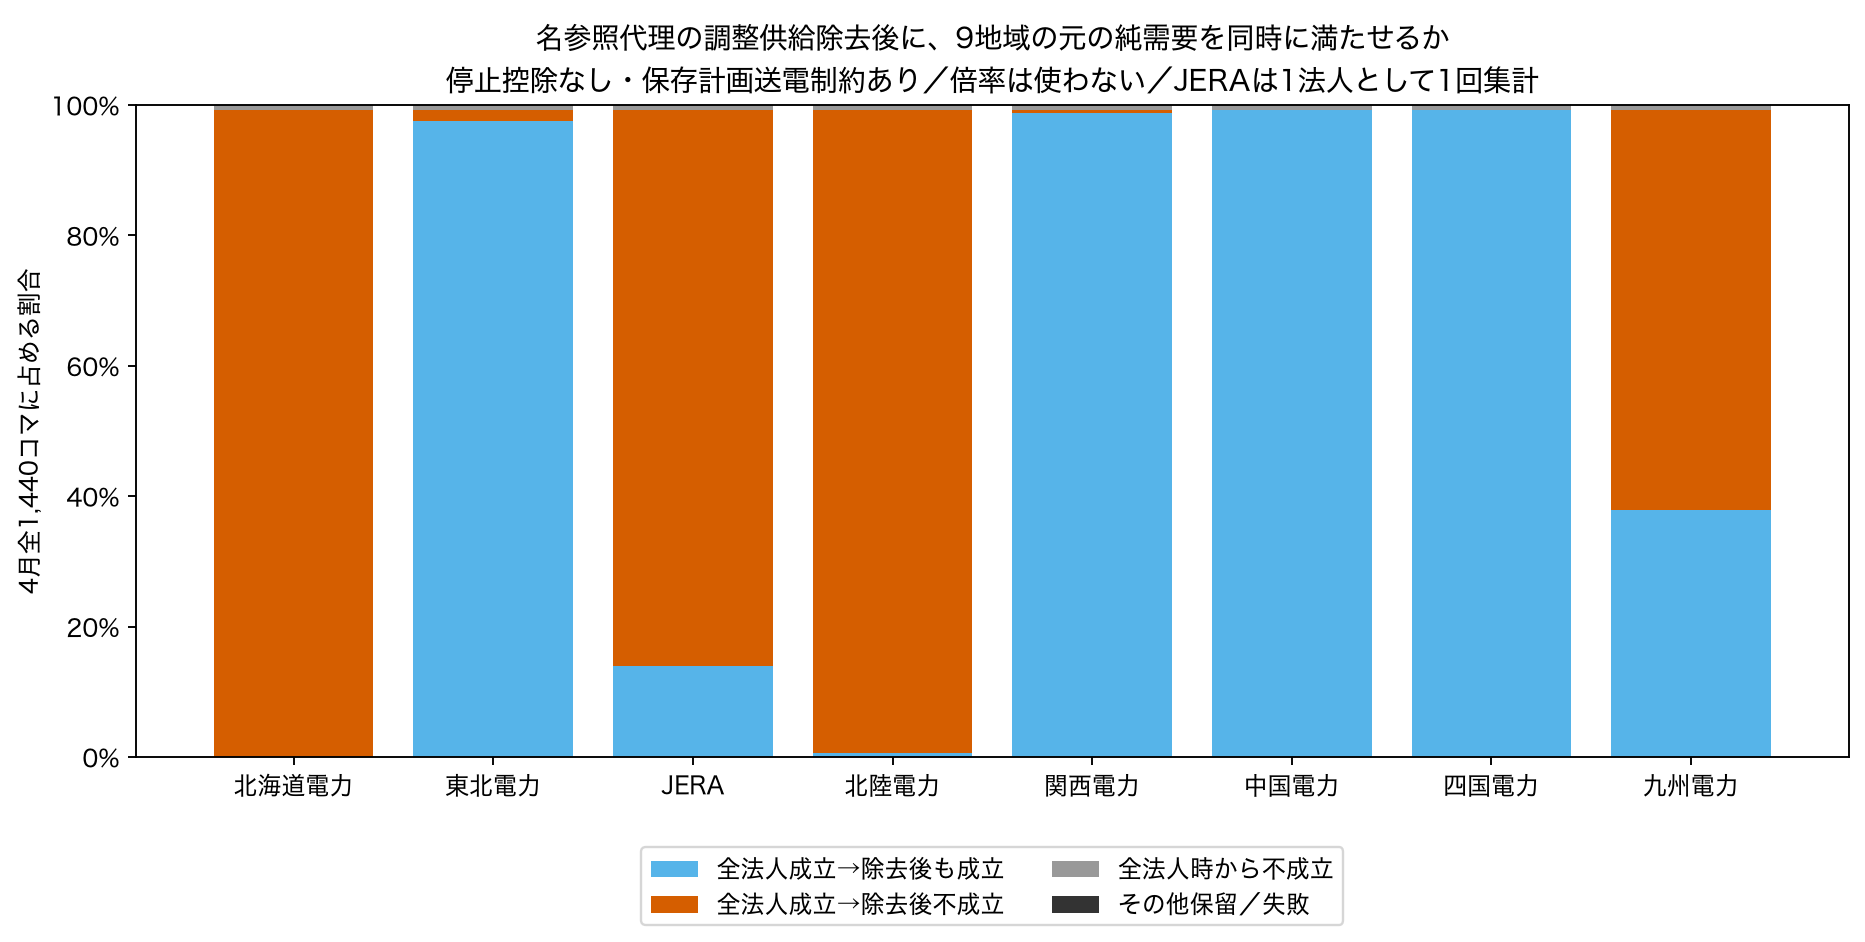

,supply_trial_scenario,network_scenario,entity_code,entity,transition,time_keys
649,reference_no_deduction,saved_plan_constraints,chugoku,中国電力株式会社,all_feasible_removed_feasible,1430
650,reference_no_deduction,saved_plan_constraints,chugoku,中国電力株式会社,all_firms_already_infeasible,10
651,reference_no_deduction,saved_plan_constraints,hokkaido,北海道電力株式会社,all_feasible_removed_infeasible,1430
652,reference_no_deduction,saved_plan_constraints,hokkaido,北海道電力株式会社,all_firms_already_infeasible,10
653,reference_no_deduction,saved_plan_constraints,hokuriku,北陸電力株式会社,all_feasible_removed_feasible,8
654,reference_no_deduction,saved_plan_constraints,hokuriku,北陸電力株式会社,all_feasible_removed_infeasible,1422
655,reference_no_deduction,saved_plan_constraints,hokuriku,北陸電力株式会社,all_firms_already_infeasible,10
656,reference_no_deduction,saved_plan_constraints,jera,株式会社JERA,all_feasible_removed_feasible,201
657,reference_no_deduction,saved_plan_constraints,jera,株式会社JERA,all_feasible_removed_infeasible,1229
658,reference_no_deduction,saved_plan_constraints,jera,株式会社JERA,all_firms_already_infeasible,10


In [6]:
show("05_nine_area_simultaneous")
sim = pd.read_csv(QA / "simultaneous_summary.csv")
display(
    sim[
        sim.supply_trial_scenario.eq("reference_no_deduction")
        & sim.network_scenario.eq("saved_plan_constraints")
    ]
)

## 5．全件データと再計算

下の既定処理は保存版の閲覧だけです。再構築を選ぶと、既存版を上書きせず新しい時刻付きディレクトリへ計算します。約13万種類のLPを含み数分かかります。問い合わせ・取得・原本変更は行いません。

In [7]:
REBUILD = False
if REBUILD:
    from datetime import datetime
    from zoneinfo import ZoneInfo

    from scripts.interpret_april_trial import run
    from src.april_trial_figures import render

    stamp = datetime.now(ZoneInfo("Asia/Tokyo")).strftime("%Y%m%dT%H%M%S")
    new_output = ROOT / "data/interim/occto/april_trial_comparison" / (stamp + "_reproduction")
    new_report = new_output / "review"
    run(ROOT, new_output, new_report)
    render(new_output, new_report)
    print("再構築先:", new_output)
else:
    for path in sorted(OUT.glob("*.parquet")):
        import pyarrow.parquet as pq

        print(path.name, f"{pq.read_metadata(path).num_rows:,}行")

all_firms_simultaneous_baseline.parquet 48,960行
all_times_with_display_categories.parquet 440,640行
multiplier_simultaneous_relationship.parquet 440,640行
nine_area_simultaneous_after_removal.parquet 391,680行
overlapping_reason_flags.parquet 440,640行
paired_stop_cases_all_times.parquet 207,360行
reference_network_pairs_all_times.parquet 12,960行
restored_reference_by_entity_time.parquet 92,160行
simultaneous_solution_samples.parquet 88行


今回の比較だけで、実際の利用可能供給や所有・契約供給の網羅性が確認されたわけではありません。停止保留・送電制約・未算定時刻の扱いを残し、4月限定の結果として読みます。